# 06 · Model Evaluation and Comparative Analysis

Everything here uses the **untouched 2023–2025 test set** (4,536 district-months, 36 target months), plus out-of-fold predictions from 2011–2022 where noted.

| Section | Content |
|---|---|
| 1 | Main comparison: MAE, RMSE, R², bias, skill scores (RQ4, RQ5) |
| 2 | Is the difference real? Bootstrap confidence intervals over months |
| 3 | Why raw-temperature R² is misleading |
| 4 | Where models succeed or fail: season, province, time |
| 5 | Residual analysis and distribution shift |
| 6 | Secondary task: extreme-heat months (Precision / Recall / F1) |
| 7 | What drives the predictions: permutation importance + SHAP |
| 8 | Spatial generalisation: leave-one-province-out |
| 9 | Summary |

In [1]:
import sys, time; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, geopandas as gpd
from sklearn.metrics import precision_recall_curve
from src import config as C, features as F, models as M, preprocessing as P, plotting as V
V.set_style(); pd.set_option("display.width", 170)
REP = C.ROOT / "reports"
pred = pd.read_parquet(C.DATA_PROCESSED / "test_predictions.parquet")
oof = pd.read_parquet(C.DATA_PROCESSED / "oof_predictions.parquet")
feat = F.load_features()
test = feat[feat["split"] == "test"].reset_index(drop=True)
dev = feat[feat["split"] != "test"].reset_index(drop=True)
params = M.load_params()
models = {n: M.load_model(n) for n in M.MODEL_ORDER}
ALL = M.BASELINE_ORDER + M.MODEL_ORDER
COL = {**{n: c for n, c in zip(M.MODEL_ORDER, V.CATEGORICAL[:4])}, "Climatology": V.MUTED, "Persistence": "#c3c2b7", "Damped persistence": V.INK_2}
y = pred[F.TARGET]
print("test rows:", len(pred), "| months:", pred["target_date"].nunique(), "| mean actual anomaly:", round(y.mean(), 3), "°C")

test rows: 4536 | months: 36 | mean actual anomaly: 0.309 °C


## 1. Main comparison (RQ4, RQ5)

In [2]:
rows = []
for n in ALL:
    rows.append({"model": n, **M.regression_metrics(y, pred[n], ref_clim=pred["Climatology"], ref_damped=pred["Damped persistence"])})
main = pd.DataFrame(rows).set_index("model")
main.to_csv(REP / "test_metrics_regression.csv")
main.round(4)

,MAE,RMSE,R2,Bias,Skill vs climatology,Skill vs damped persistence
model,,,,,,
Climatology,1.3840,1.7555,-0.0320,-0.3091,0.0000,-0.0804
Persistence,1.6318,2.0949,-0.4696,-0.0350,-0.4241,-0.5386
Damped persistence,1.3332,1.6889,0.0448,-0.2242,0.0744,0.0000
Ridge,1.3326,1.6733,0.0623,-0.2875,0.0914,0.0183
Random Forest,1.3508,1.7111,0.0196,-0.2706,0.0500,-0.0264
XGBoost,1.3433,1.6946,0.0384,-0.2641,0.0682,-0.0068
SVR,1.3575,1.7059,0.0255,-0.3285,0.0557,-0.0202


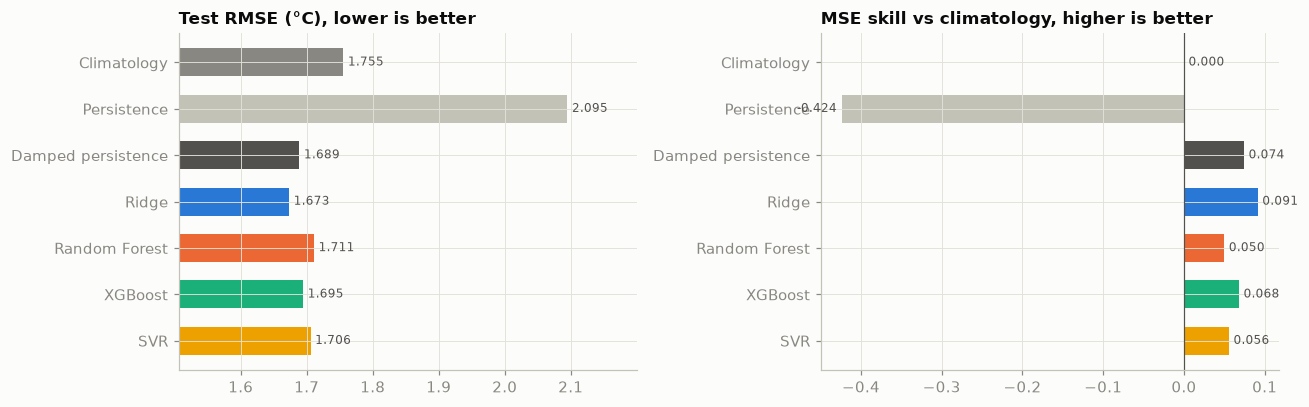

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, title in [(axes[0], "RMSE", "Test RMSE (°C), lower is better"), (axes[1], "Skill vs climatology", "MSE skill vs climatology, higher is better")]:
    vals = main.loc[ALL, metric]
    ax.barh(ALL[::-1], vals[::-1], color=[COL[n] for n in ALL[::-1]], height=.6)
    for i, v in enumerate(vals[::-1]):
        ax.annotate(f"{v:.3f}", (v, i), xytext=(3 if v >= 0 else -3, 0), textcoords="offset points", va="center",
                    ha="left" if v >= 0 else "right", fontsize=8, color=V.INK_2)
    ax.set_title(title)
    if metric == "RMSE": ax.set_xlim(vals.min() * .9, vals.max() * 1.05)
    else: ax.axvline(0, color=V.INK_2, linewidth=.8)
fig.tight_layout(); V.save(fig, "ml_02_test_comparison"); plt.show()

## 2. Is the difference real? Bootstrap confidence intervals

Test errors are not independent across districts in the same month. We therefore resample the **36 test months** with replacement (1,000 times) and recompute each skill score, giving a 95% confidence interval.
If an interval excludes 0, the model is reliably better (or worse) than the reference.

In [4]:
ci_rows = []
for n in M.MODEL_ORDER + ["Persistence", "Damped persistence"]:
    for ref in ["Climatology", "Damped persistence"]:
        if n == ref: continue
        pt, lo, hi = M.bootstrap_skill(pred, n, ref)
        ci_rows.append({"model": n, "reference": ref, "skill": pt, "ci_low": lo, "ci_high": hi, "significant": (lo > 0) or (hi < 0)})
ci = pd.DataFrame(ci_rows)
ci.to_csv(REP / "test_skill_bootstrap_ci.csv", index=False)
ci.round(4)

,model,reference,skill,ci_low,ci_high,significant
0,Ridge,Climatology,0.0914,-0.0321,0.1963,False
1,Ridge,Damped persistence,0.0183,-0.0538,0.0758,False
2,Random Forest,Climatology,0.0500,-0.0656,0.1520,False
3,Random Forest,Damped persistence,-0.0264,-0.0862,0.0256,False
4,XGBoost,Climatology,0.0682,-0.0709,0.1899,False
5,XGBoost,Damped persistence,-0.0068,-0.0760,0.0636,False
6,SVR,Climatology,0.0557,-0.0982,0.1911,False
7,SVR,Damped persistence,-0.0202,-0.1278,0.0807,False
8,Persistence,Climatology,-0.4241,-1.0618,0.0757,False
9,Persistence,Damped persistence,-0.5386,-1.0609,-0.1195,True


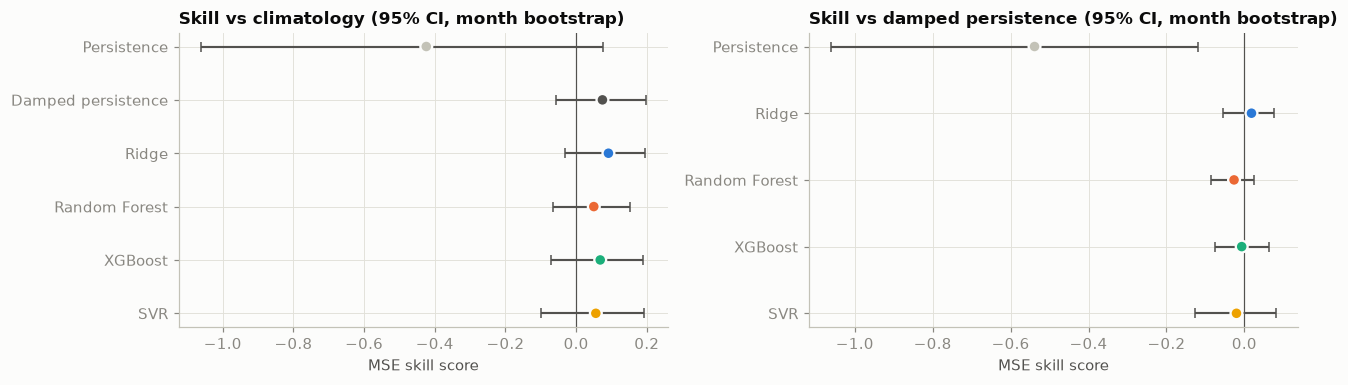

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, ref in zip(axes, ["Climatology", "Damped persistence"]):
    c = ci[(ci.reference == ref)].set_index("model").reindex([m for m in ["Persistence", "Damped persistence"] + M.MODEL_ORDER if m != ref]).dropna()
    yy = np.arange(len(c))[::-1]
    ax.errorbar(c["skill"], yy, xerr=[c["skill"] - c["ci_low"], c["ci_high"] - c["skill"]], fmt="none", ecolor=V.INK_2, elinewidth=1.4, capsize=3)
    ax.scatter(c["skill"], yy, s=60, color=[COL[m] for m in c.index], zorder=3, edgecolor=V.SURFACE, linewidth=1.5)
    ax.axvline(0, color=V.INK_2, linewidth=.8)
    ax.set_yticks(yy); ax.set_yticklabels(c.index)
    ax.set(title=f"Skill vs {ref.lower()} (95% CI, month bootstrap)", xlabel="MSE skill score")
fig.tight_layout(); V.save(fig, "ml_03_skill_ci"); plt.show()

## 3. Why raw-temperature R² would be misleading

Adding each district's climatology back to the predicted anomaly gives a prediction of actual Tmax in °C. Even the **climatology baseline**, which knows nothing about the current weather, reaches an R² near 1, because the seasonal cycle and geography explain almost all the variance. This is why the project evaluates **anomalies** (PLAN.md, D1).

In [6]:
raw = pd.DataFrame({n: M.regression_metrics(pred["target_tmax"], pred["target_tmax_clim"] + pred[n]) for n in ALL}).T[["RMSE", "R2"]]
raw.columns = ["RMSE on raw Tmax (°C)", "R² on raw Tmax"]
raw.join(main[["R2"]].rename(columns={"R2": "R² on anomaly"})).round(4)

,RMSE on raw Tmax (°C),R² on raw Tmax,R² on anomaly
Climatology,1.7555,0.9802,-0.0320
Persistence,2.0949,0.9719,-0.4696
Damped persistence,1.6889,0.9817,0.0448
Ridge,1.6733,0.9821,0.0623
Random Forest,1.7111,0.9812,0.0196
XGBoost,1.6946,0.9816,0.0384
SVR,1.7059,0.9813,0.0255


## 4. Where do models succeed or fail?

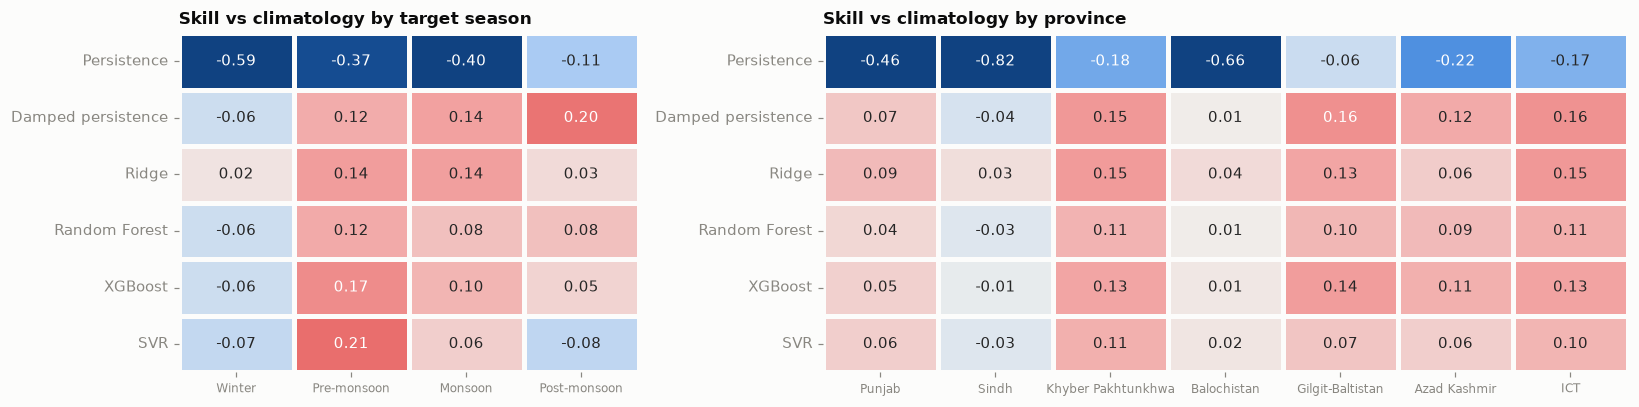

,Winter (DJF),Pre-monsoon (MAM),Monsoon (JJAS),Post-monsoon (ON)
Persistence,-0.588,-0.373,-0.400,-0.113
Damped persistence,-0.058,0.118,0.137,0.202
Ridge,0.019,0.141,0.138,0.035
Random Forest,-0.058,0.119,0.082,0.084
XGBoost,-0.058,0.168,0.100,0.050
SVR,-0.075,0.212,0.058,-0.078


In [7]:
season_skill = pd.DataFrame({s: {n: 1 - np.mean((g[n] - g[F.TARGET]) ** 2) / np.mean(g[F.TARGET] ** 2) for n in ALL[1:]}
                             for s, g in pred.groupby("target_season", observed=True)})[P.SEASON_ORDER]
prov_skill = pd.DataFrame({p: {n: 1 - np.mean((g[n] - g[F.TARGET]) ** 2) / np.mean(g[F.TARGET] ** 2) for n in ALL[1:]}
                           for p, g in pred.groupby("province")})[[p for p in V.PROVINCE_ORDER if p in pred.province.unique()]]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [4, 7]})
for ax, t, title in [(axes[0], season_skill, "Skill vs climatology by target season"), (axes[1], prov_skill, "Skill vs climatology by province")]:
    sns.heatmap(t, annot=True, fmt=".2f", cmap=V.DIVERGING, center=0, vmin=-.4, vmax=.4, linewidths=2, linecolor=V.SURFACE, cbar=False, ax=ax)
    ax.set_title(title); ax.grid(False); ax.set_xticklabels([x.get_text().split(" (")[0].replace("Islamabad Capital Territory", "ICT") for x in ax.get_xticklabels()], rotation=0, fontsize=8)
fig.tight_layout(); V.save(fig, "ml_04_skill_by_season_province"); plt.show()
season_skill.round(3)

Best model on test RMSE: Ridge


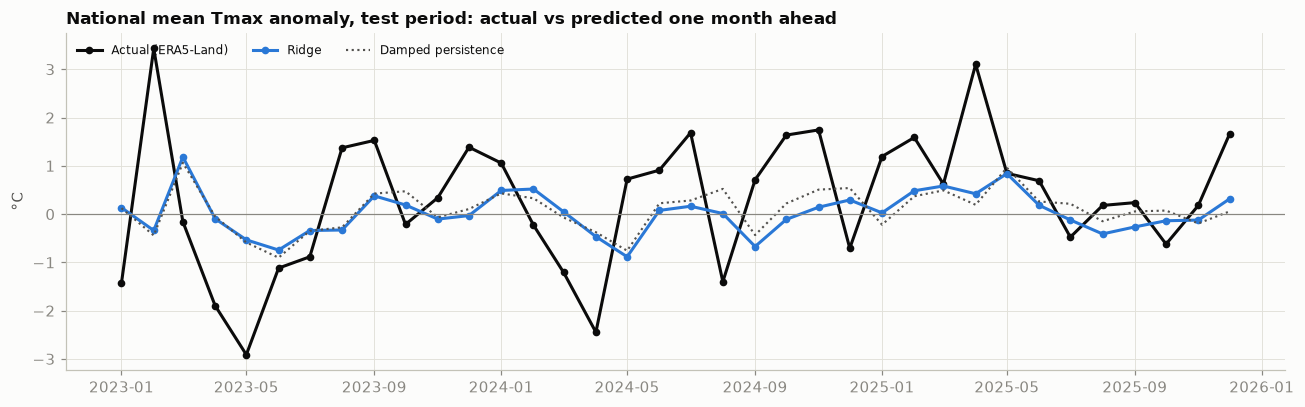

Correlation of national monthly means, actual vs Ridge : 0.249


In [8]:
best = main.loc[M.MODEL_ORDER, "RMSE"].idxmin()
print("Best model on test RMSE:", best)
nat = pred.groupby("target_date")[[F.TARGET] + ALL].mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(nat.index, nat[F.TARGET], color=V.INK, linewidth=2, marker="o", markersize=4, label="Actual (ERA5-Land)")
ax.plot(nat.index, nat[best], color=COL[best], linewidth=2, marker="o", markersize=4, label=f"{best}")
ax.plot(nat.index, nat["Damped persistence"], color=V.INK_2, linewidth=1.4, linestyle=":", label="Damped persistence")
ax.axhline(0, color=V.MUTED, linewidth=.8)
ax.set(title="National mean Tmax anomaly, test period: actual vs predicted one month ahead", ylabel="°C")
ax.legend(fontsize=8, loc="upper left", ncol=3)
fig.tight_layout(); V.save(fig, "ml_05_test_timeseries"); plt.show()
print("Correlation of national monthly means, actual vs", best, ":", round(nat[F.TARGET].corr(nat[best]), 3))

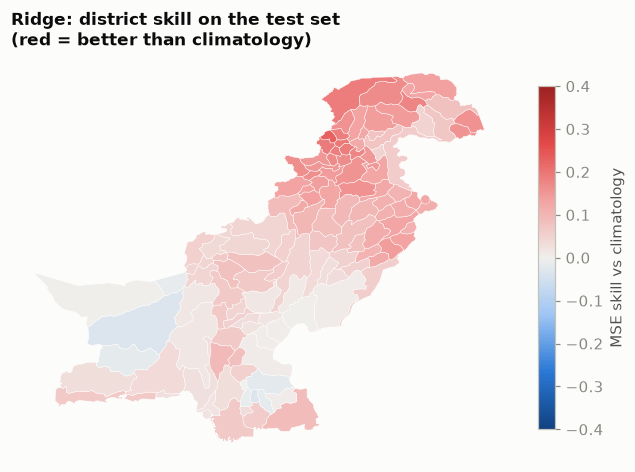

districts where Ridge beats climatology: 118 / 126


In [9]:
gdf = gpd.read_file(C.DATA_RAW / "districts.geojson")[["district_id", "geometry"]]
dsk = pred.groupby("district_id").apply(lambda g: 1 - np.mean((g[best] - g[F.TARGET]) ** 2) / np.mean(g[F.TARGET] ** 2), include_groups=False).rename("skill")
g = gdf.merge(dsk, left_on="district_id", right_index=True)
fig, ax = plt.subplots(figsize=(6, 5.5))
g.plot(column="skill", cmap=V.DIVERGING, norm=V.symmetric_norm(None, .4), ax=ax, edgecolor="white", linewidth=.3, legend=True,
       legend_kwds={"shrink": .6, "label": "MSE skill vs climatology"})
ax.set_title(f"{best}: district skill on the test set\n(red = better than climatology)"); V.map_axes(ax)
fig.tight_layout(); V.save(fig, "ml_06_district_skill_map"); plt.show()
print(f"districts where {best} beats climatology: {(dsk > 0).sum()} / {len(dsk)}")

## 5. Residual analysis and distribution shift

* **Shrinkage:** with weak predictability, the optimal forecast is cautious. Predictions cluster near 0 and the actual-vs-predicted slope is far below 1. This is correct behaviour under uncertainty, not a bug.
* **Bias:** the test period is warmer than 2000–2022 (mean actual anomaly > 0). A negative mean residual means the models under-predict this warmth.
* **Extremes:** tree models cannot output values beyond what they saw in training. We check errors in the warmest test months.

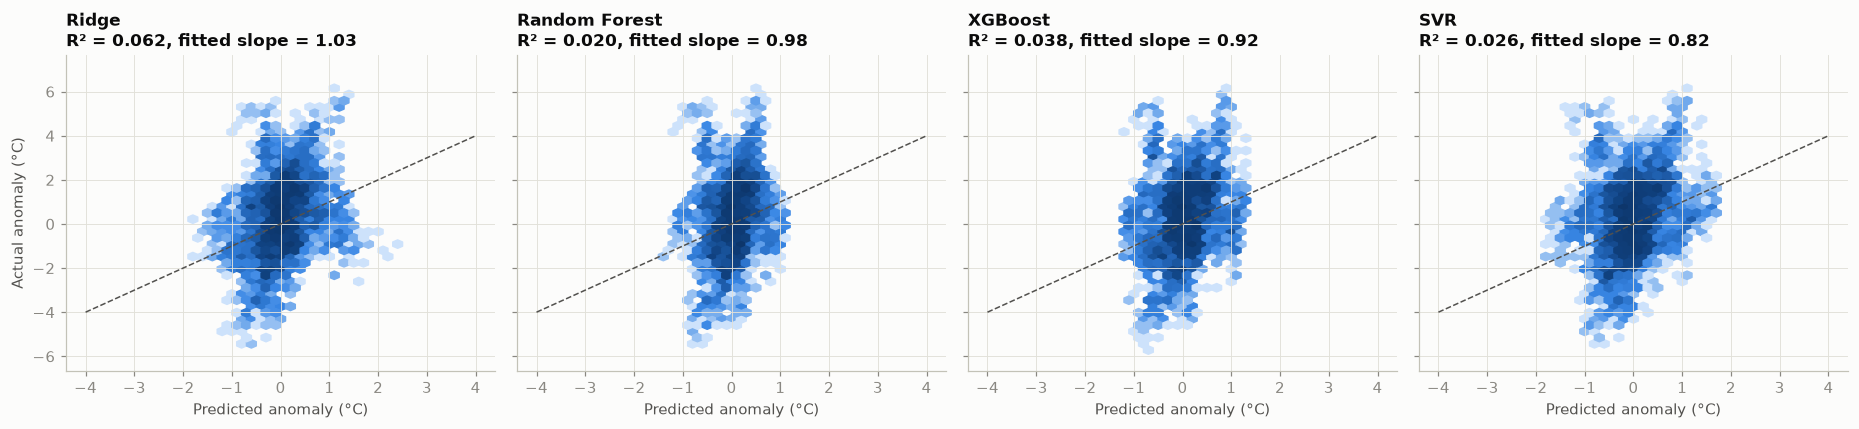

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True, sharey=True)
for ax, n in zip(axes, M.MODEL_ORDER):
    ax.hexbin(pred[n], y, gridsize=40, cmap=V.SEQ_BLUE, bins="log", mincnt=1, extent=(-4, 4, -6, 7))
    ax.plot([-4, 4], [-4, 4], color=V.INK_2, linestyle="--", linewidth=1)
    slope = np.polyfit(pred[n], y, 1)[0]
    ax.set(title=f"{n}\nR² = {main.loc[n, 'R2']:.3f}, fitted slope = {slope:.2f}", xlabel="Predicted anomaly (°C)")
axes[0].set_ylabel("Actual anomaly (°C)")
fig.tight_layout(); V.save(fig, "ml_07_actual_vs_predicted"); plt.show()

In [11]:
res = pd.DataFrame({n: y - pred[n] for n in ALL})
bins = pd.cut(y, [-np.inf, -2, -1, 0, 1, 2, np.inf], labels=["< −2", "−2…−1", "−1…0", "0…1", "1…2", "> 2"])
tab = res.groupby(bins, observed=True).mean().T
tab["n rows"] = np.nan
tab.loc["count"] = bins.value_counts().reindex(tab.columns[:-1]).values.tolist() + [np.nan]
print("Mean residual (actual − predicted, °C) by actual-anomaly bin:")
tab.drop(columns="n rows").round(2)

Mean residual (actual − predicted, °C) by actual-anomaly bin:


target_anom,< −2,−2…−1,−1…0,0…1,1…2,> 2
Climatology,-2.91,-1.42,-0.49,0.51,1.47,3.02
Persistence,-2.13,-1.07,-0.76,0.16,0.81,2.21
Damped persistence,-2.67,-1.31,-0.57,0.40,1.27,2.77
Ridge,-2.58,-1.26,-0.50,0.46,1.35,2.78
Random Forest,-2.72,-1.37,-0.53,0.45,1.35,2.91
XGBoost,-2.67,-1.33,-0.53,0.44,1.33,2.83
SVR,-2.54,-1.29,-0.42,0.50,1.36,2.87
count,383.00,590.00,988.00,1014.00,896.00,665.00


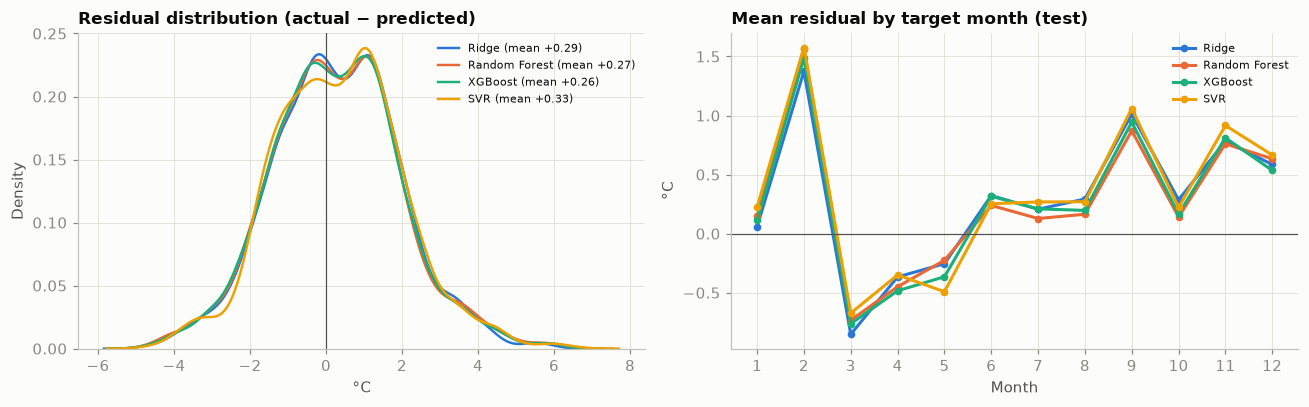

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
for n in M.MODEL_ORDER:
    sns.kdeplot(res[n], ax=ax, color=COL[n], label=f"{n} (mean {res[n].mean():+.2f})", linewidth=1.6)
ax.axvline(0, color=V.INK_2, linewidth=.8); ax.set(title="Residual distribution (actual − predicted)", xlabel="°C"); ax.legend(fontsize=7)
ax = axes[1]
mres = res.groupby(pred["target_month"])[M.MODEL_ORDER].mean()
for n in M.MODEL_ORDER:
    ax.plot(mres.index, mres[n], color=COL[n], marker="o", markersize=4, label=n)
ax.axhline(0, color=V.INK_2, linewidth=.8)
ax.set(title="Mean residual by target month (test)", xlabel="Month", ylabel="°C", xticks=range(1, 13)); ax.legend(fontsize=7)
fig.tight_layout(); V.save(fig, "ml_08_residuals"); plt.show()

## 6. Secondary task: extreme-heat months

**Event:** next month's Tmax anomaly exceeds the 90th percentile of training anomalies (PLAN.md, D3).
**Score:** each regressor's predicted anomaly, so no extra models are needed. A higher predicted anomaly means more likely extreme.
**Decision threshold:** chosen to maximise F1 on the **2011–2022 out-of-fold** predictions, then applied unchanged to the test set. Tuning it on the test set would inflate F1.
ROC-AUC and PR-AUC measure ranking quality without any threshold. For PR-AUC, the no-skill reference equals the event rate.

In [13]:
thr_event = F.extreme_threshold(feat)
y_oof = (oof[F.TARGET] > thr_event).astype(int)
y_test = (y > thr_event).astype(int)
print(f"Event threshold: anomaly > {thr_event:.2f} °C | event rate: OOF {y_oof.mean():.1%}, test {y_test.mean():.1%}")
phi = float(open(C.MODELS_DIR / "phi.txt").read())
oof["Damped persistence"] = phi * oof["tmax_anom_l0"]
rows, curves = [], {}
for n in ["Damped persistence"] + M.MODEL_ORDER:
    dthr = M.best_f1_threshold(y_oof, oof[n])
    rows.append({"model": n, "decision threshold (°C)": dthr, **M.classification_metrics(y_test, pred[n], dthr)})
    curves[n] = precision_recall_curve(y_test, pred[n])
cls = pd.DataFrame(rows).set_index("model")
cls.to_csv(REP / "test_metrics_extreme_heat.csv")
cls.round(3)

Event threshold: anomaly > 1.76 °C | event rate: OOF 9.6%, test 18.2%


,decision threshold (°C),Precision,Recall,F1,ROC-AUC,PR-AUC,Predicted positive %
model,,,,,,,
Damped persistence,0.426,0.263,0.365,0.306,0.632,0.239,25.243
Ridge,0.130,0.275,0.584,0.374,0.664,0.262,38.558
Random Forest,0.085,0.244,0.635,0.352,0.617,0.242,47.332
XGBoost,0.143,0.255,0.570,0.352,0.625,0.260,40.653
SVR,0.194,0.295,0.508,0.374,0.630,0.273,31.283


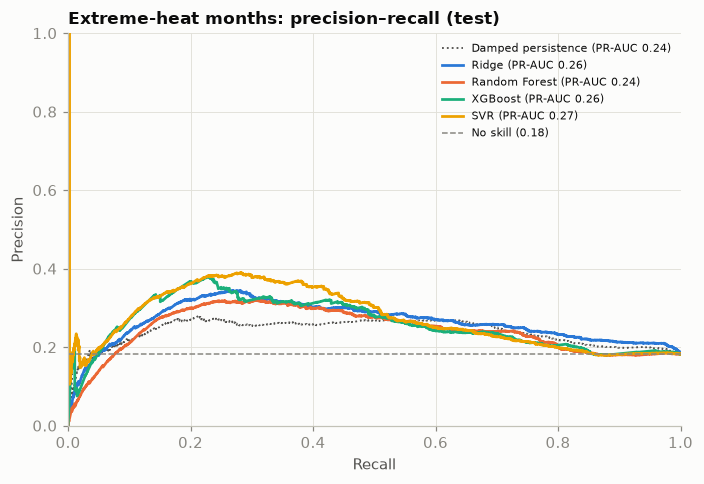

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for n, (p, r, _) in curves.items():
    ax.plot(r, p, color=COL[n], linewidth=1.8 if n != "Damped persistence" else 1.2, linestyle="-" if n != "Damped persistence" else ":",
            label=f"{n} (PR-AUC {cls.loc[n, 'PR-AUC']:.2f})")
ax.axhline(y_test.mean(), color=V.MUTED, linestyle="--", linewidth=1, label=f"No skill ({y_test.mean():.2f})")
ax.set(title="Extreme-heat months: precision–recall (test)", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=7)
fig.tight_layout(); V.save(fig, "ml_09_extreme_heat_pr"); plt.show()

## 7. What drives the predictions?

**Grouped permutation importance (all four models, test set):** shuffle all features of one group together and measure how much RMSE gets worse. Grouping is needed because features within a group are strongly correlated (notebook 04). Shuffling one of them alone would understate the group's importance, since its correlated partners still carry the information.
**SHAP (XGBoost):** explains each individual prediction as a sum of feature contributions, showing both importance and direction.

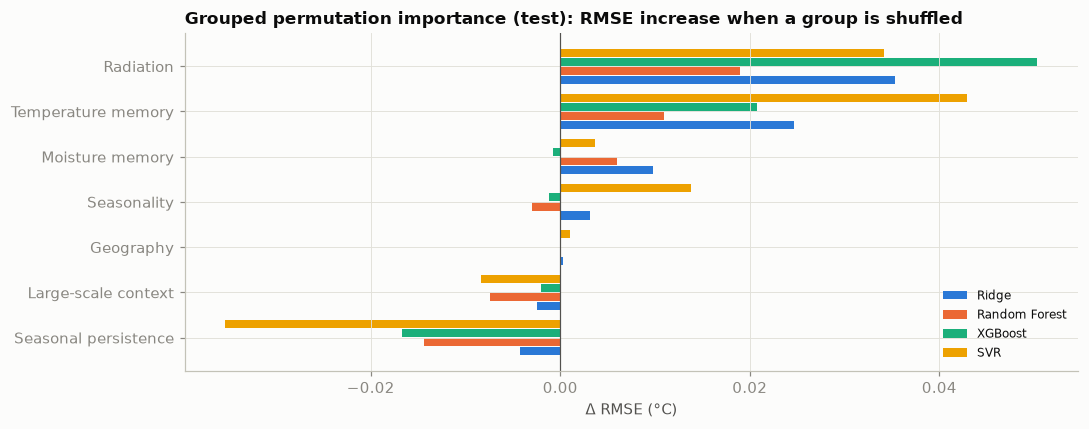

,Ridge,Random Forest,XGBoost,SVR
Temperature memory,0.0247,0.0110,0.0207,0.0430
Moisture memory,0.0098,0.0059,-0.0008,0.0037
Radiation,0.0353,0.0190,0.0503,0.0341
Large-scale context,-0.0025,-0.0074,-0.0020,-0.0084
Seasonal persistence,-0.0042,-0.0144,-0.0167,-0.0353
Seasonality,0.0032,-0.0030,-0.0012,0.0138
Geography,0.0003,0.0000,0.0000,0.0011


In [15]:
rng = np.random.default_rng(C.RANDOM_SEED)
Xte = test[F.FEATURES]
base_rmse = {n: np.sqrt(np.mean((models[n].predict(Xte) - y) ** 2)) for n in M.MODEL_ORDER}
imp = {}
for n in M.MODEL_ORDER:
    imp[n] = {}
    for gname, cols in F.FEATURE_GROUPS.items():
        incs = []
        for _ in range(5):
            Xp = Xte.copy()
            idx = rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].to_numpy()[idx]          # shuffle the group's rows jointly
            incs.append(np.sqrt(np.mean((models[n].predict(Xp) - y) ** 2)) - base_rmse[n])
        imp[n][gname] = np.mean(incs)
imp = pd.DataFrame(imp)
imp.to_csv(REP / "permutation_importance_groups.csv")
fig, ax = plt.subplots(figsize=(10, 4))
order = imp.mean(axis=1).sort_values().index
w = .2
for i, n in enumerate(M.MODEL_ORDER):
    ax.barh(np.arange(len(order)) + (i - 1.5) * w, imp.loc[order, n], height=w * .9, color=COL[n], label=n)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.axvline(0, color=V.INK_2, linewidth=.8)
ax.set(title="Grouped permutation importance (test): RMSE increase when a group is shuffled", xlabel="Δ RMSE (°C)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); V.save(fig, "ml_10_permutation_importance"); plt.show()
imp.round(4)

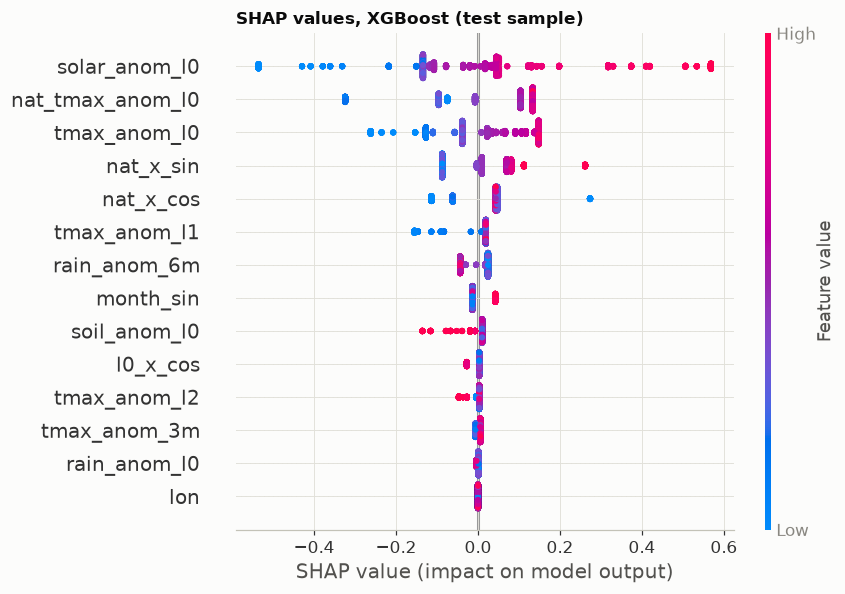

solar_anom_l0       0.1605
nat_tmax_anom_l0    0.1200
tmax_anom_l0        0.0951
nat_x_sin           0.0659
nat_x_cos           0.0626
tmax_anom_l1        0.0323
rain_anom_6m        0.0316
month_sin           0.0209
soil_anom_l0        0.0139
l0_x_cos            0.0065
dtype: float32

In [16]:
import shap
xgb = models["XGBoost"]
sample = Xte.sample(3000, random_state=C.RANDOM_SEED)
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(sample)
plt.figure()
shap.summary_plot(sv, sample, show=False, max_display=14, plot_size=(8, 5.5))
plt.title("SHAP values, XGBoost (test sample)", loc="left", fontweight="bold")
plt.tight_layout(); V.save(plt.gcf(), "ml_11_shap_summary"); plt.show()
shap_imp = pd.Series(np.abs(sv).mean(0), index=sample.columns).sort_values(ascending=False)
shap_imp.to_csv(REP / "shap_mean_abs_xgboost.csv")
shap_imp.round(4).head(10)

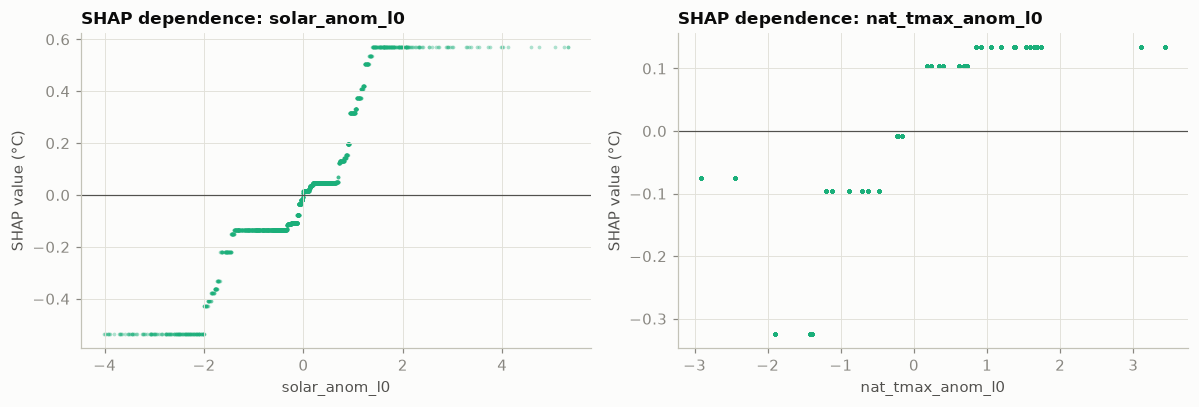

In [17]:
top2 = shap_imp.index[:2]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, f in zip(axes, top2):
    j = list(sample.columns).index(f)
    ax.scatter(sample[f], sv[:, j], s=6, alpha=.35, color=V.CATEGORICAL[2], linewidth=0)
    ax.axhline(0, color=V.INK_2, linewidth=.8)
    ax.set(title=f"SHAP dependence: {f}", xlabel=f, ylabel="SHAP value (°C)")
fig.tight_layout(); V.save(fig, "ml_12_shap_dependence"); plt.show()

## 8. Spatial generalisation: leave-one-province-out (LOPO)

**Question:** can the models predict a province they have never seen?
For each of the five large provinces, we refit every model (same hyperparameters) on 2000–2022 data from **all other provinces**, then predict that province's 2023–2025 test months.
We compare against the normal models, which saw that province during training. A small gap means the learned relationships transfer across regions.
AJK and ICT (one district each) are always kept in training.

In [18]:
lopo_rows = []
held = ["Punjab", "Sindh", "Khyber Pakhtunkhwa", "Balochistan", "Gilgit-Baltistan"]
t0 = time.time()
for prov in held:
    trn = dev[dev["province"] != prov]
    tst_mask = pred["province"] == prov
    tst = test[test["province"] == prov]
    yt = tst[F.TARGET].to_numpy()
    clim_mse = np.mean(yt ** 2)
    for n in M.MODEL_ORDER:
        m = M.fit_model(n, params[n], trn)
        p_lopo = m.predict(tst[F.FEATURES])
        p_full = pred.loc[tst_mask, n].to_numpy()
        lopo_rows.append({"province": prov, "model": n, "rows": len(tst),
                          "RMSE (seen)": np.sqrt(np.mean((p_full - yt) ** 2)), "RMSE (held out)": np.sqrt(np.mean((p_lopo - yt) ** 2)),
                          "skill (seen)": 1 - np.mean((p_full - yt) ** 2) / clim_mse, "skill (held out)": 1 - np.mean((p_lopo - yt) ** 2) / clim_mse})
    print(f"{prov} done ({(time.time() - t0) / 60:.1f} min)")
lopo = pd.DataFrame(lopo_rows)
lopo["skill drop"] = lopo["skill (seen)"] - lopo["skill (held out)"]
lopo.to_csv(REP / "lopo_results.csv", index=False)
lopo.pivot(index="province", columns="model", values="skill (held out)")[M.MODEL_ORDER].round(3)

Punjab done (0.6 min)


Sindh done (1.3 min)


Khyber Pakhtunkhwa done (2.0 min)


Balochistan done (2.6 min)


Gilgit-Baltistan done (3.5 min)


model,Ridge,Random Forest,XGBoost,SVR
province,,,,
Balochistan,0.036,0.021,0.022,0.029
Gilgit-Baltistan,0.129,0.080,0.134,-0.047
Khyber Pakhtunkhwa,0.143,0.096,0.129,0.128
Punjab,0.088,0.043,0.051,0.057
Sindh,0.028,-0.022,-0.018,-0.010


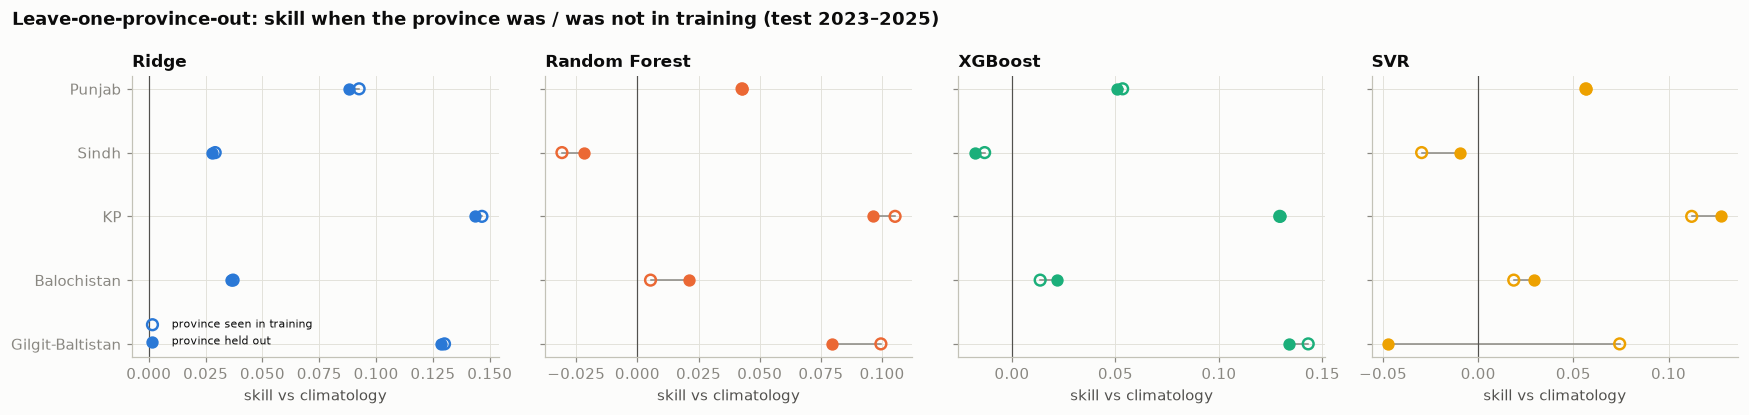

,skill (seen),skill (held out),skill drop
model,,,
Ridge,0.0871,0.0848,0.0023
Random Forest,0.0444,0.0436,0.0008
XGBoost,0.0653,0.0635,0.0017
SVR,0.0464,0.0313,0.0151


In [19]:
fig, axes = plt.subplots(1, len(M.MODEL_ORDER), figsize=(16, 3.8), sharey=True)
for ax, n in zip(axes, M.MODEL_ORDER):
    l = lopo[lopo.model == n].set_index("province").loc[held]
    yy = np.arange(len(l))[::-1]
    ax.scatter(l["skill (seen)"], yy, s=50, facecolor="none", edgecolor=COL[n], linewidth=1.6, label="province seen in training", zorder=3)
    ax.scatter(l["skill (held out)"], yy, s=50, color=COL[n], label="province held out", zorder=3)
    for k, (a, b) in enumerate(zip(l["skill (seen)"], l["skill (held out)"])):
        ax.plot([a, b], [yy[k]] * 2, color=V.MUTED, linewidth=1)
    ax.axvline(0, color=V.INK_2, linewidth=.8)
    ax.set_yticks(yy); ax.set_yticklabels([p.replace("Khyber Pakhtunkhwa", "KP") for p in held])
    ax.set(title=n, xlabel="skill vs climatology")
axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Leave-one-province-out: skill when the province was / was not in training (test 2023–2025)", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); V.save(fig, "ml_13_lopo"); plt.show()
lopo.groupby("model")[["skill (seen)", "skill (held out)", "skill drop"]].mean().loc[M.MODEL_ORDER].round(4)

## 9. Summary of results

All numbers come from the cells above (test set 2023–2025, 126 districts × 36 months).

**M1. All four ML models beat climatology, but only Ridge edges past damped persistence (RQ4, RQ5).**
Test MSE skill vs climatology: Ridge +9.1%, XGBoost +6.8%, SVR +5.6%, Random Forest +5.0%, against +7.4% for the one-parameter damped persistence.
Ridge is the best model (RMSE 1.673 °C vs 1.756 for climatology and 1.689 for damped persistence). The three non-linear models are slightly *worse* than damped persistence. Raw persistence is far worse than everything (−42%): repeating last month's anomaly unchanged over-reacts to noise.

**M2. The differences are not statistically significant.** With only 36 test months, the 95% bootstrap intervals for every ML model's skill include 0, both against climatology and against damped persistence. The only significant result is that raw persistence is worse than damped persistence. The honest conclusion: one-month-ahead district Tmax anomalies are **weakly predictable**, and model choice matters less than regularisation.

**M3. Raw-temperature R² is misleading.** On actual Tmax in °C, every method, including climatology, scores R² ≈ 0.98. On the anomaly target, R² is between −0.03 and 0.06. This justifies the anomaly target (PLAN.md, D1).

**M4. Skill depends on season and place.** Skill is highest for pre-monsoon and monsoon targets (Ridge +0.14; SVR +0.21 for pre-monsoon) and close to zero in winter. Ridge beats climatology in 118 of 126 districts. Nationally, predicted and actual monthly anomalies correlate at r = 0.25: the models catch the sign of many months but miss the large swings (e.g. Feb 2023, Apr 2025).

**M5. Systematic under-prediction in a warming climate.** The test period averages +0.31 °C above the 2000–2019 climatology, and every model under-predicts by 0.26–0.33 °C (bias column). Models trained on anomalies that average zero are anchored to the past climate. Predictions are also strongly shrunk towards zero: the warmest months (anomaly > 2 °C) are under-predicted by about 2.8 °C. That is the cautious forecast you get under weak predictability, but it hurts exactly where heat risk matters.

**M6. ML adds more value for extreme heat than for average error.** Event rate: 18.2% of test district-months vs 9.6% in 2011–2022, another sign of warming. With thresholds chosen on out-of-fold data, Ridge and SVR reach F1 = 0.37 against 0.31 for damped persistence. PR-AUC is 0.24–0.27 against a no-skill level of 0.18.

**M7. What the models use.** Grouped permutation importance and SHAP agree: the **solar-radiation anomaly** is the strongest predictor (sunny, clear-sky months tend to precede warm months), followed by **temperature memory** and the national anomaly. Geography contributes nothing, as expected for anomalies. The seasonal-persistence interactions helped in cross-validation but have *negative* importance on the test set. Their benefit did not carry over to 2023–2025, a reminder that small CV gains in a weak-signal problem can be noise.

**M8. The relationships generalise across regions.** Leave-one-province-out costs almost nothing: mean skill drop ≤ 0.015 for all models, and ≤ 0.002 for Ridge. The models learn physical, region-independent relations (persistence, radiation) rather than memorising districts. Skill is highest in KP and Gilgit-Baltistan and lowest in Sindh.

**Implication for future work.** Local, lagged reanalysis variables carry little information beyond persistence at a one-month lead. Gains are more likely from **large-scale drivers** (ENSO / Indian Ocean SST indices, snow cover) and from explicitly modelling the warming trend to remove the bias in M5.